# Flight crew scheduling

A small regional airline has published next week's flights. Every flight needs a pilot and a flight
attendant, and every crew member lives near one of two bases. The question is **who works which
seat**, so that nobody is in two places at once, each crew member's flights connect, and as many
people as possible start and finish their roster at home.

In this notebook you will:

1. describe a three-day flight programme as Python objects,
2. solve it and draw the roster as a crew Gantt chart,
3. check the result yourself, without trusting the solver's score,
4. change the rules so that a paid transfer can bring crew home,
5. shrink the crew and see which rule gives way first,
6. restart from an existing roster, and replan around a sick call with pinned seats.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
from datetime import date, datetime, timedelta
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

from optimaru import flight_crew_scheduling as fc
from optimaru.flight_crew_scheduling import constraints as rules
from optimaru.flight_crew_scheduling.models import (
    AirportModel, EmployeeModel, FlightAssignmentModel, FlightCrewScheduleModel, FlightModel,
)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the flight programme

Four kinds of objects make up a schedule. References between them are plain strings: airport codes,
flight numbers and crew ids. Times are `datetime` values, and a naive datetime is read as UTC.

| Object | What it holds |
| --- | --- |
| `AirportModel` | an airport code, with an optional name and position |
| `FlightModel` | one flight: number, departure and arrival airport, departure and arrival time |
| `EmployeeModel` | one crew member: home airport, skills, days they cannot fly |
| `FlightAssignmentModel` | one seat on one flight and its skill. **The solver fills in `employee`.** |

The airline below is fictional. It has two crew bases, Aldermere (`ALD`) and Brackwater (`BRK`), and
four outstations. Six rotations fly every day, each made of two flights. Four of them come back to
the base they left. The other two leave `ALD` and finish at `BRK`, and nothing flies the other way,
so the programme keeps moving crew away from `ALD`.

In [2]:
FIRST_DAY = datetime(2030, 3, 4)
DAYS = 3
BASES = ["ALD", "BRK"]
AIRPORTS = [*BASES, "CAR", "DUN", "EVE", "FEN"]

LEG_HOURS = {
    ("ALD", "CAR"): 2.0, ("ALD", "DUN"): 2.5, ("ALD", "EVE"): 3.0,
    ("BRK", "CAR"): 3.0, ("BRK", "DUN"): 2.5, ("BRK", "EVE"): 2.0, ("BRK", "FEN"): 2.0,
}
ROTATIONS = [  # stops, earliest departure hour
    (("ALD", "CAR", "ALD"), 6.0),
    (("ALD", "DUN", "BRK"), 6.5),
    (("BRK", "EVE", "BRK"), 6.0),
    (("BRK", "FEN", "BRK"), 12.5),
    (("ALD", "EVE", "ALD"), 12.5),
    (("ALD", "CAR", "BRK"), 13.0),
]
TURNAROUND = timedelta(minutes=45)


def leg_time(start, end):
    return timedelta(hours=LEG_HOURS[tuple(sorted((start, end)))])


rng = np.random.default_rng(11)
flights, rotation_of = [], {}
for day in range(DAYS):
    for r, (stops, earliest) in enumerate(ROTATIONS):
        departure = FIRST_DAY + timedelta(days=day, hours=earliest + 0.25 * int(rng.integers(0, 3)))
        for leg, (start, end) in enumerate(zip(stops, stops[1:])):
            arrival = departure + leg_time(start, end)
            number = f"NC{100 * (day + 1) + 2 * r + leg}"
            flights.append(FlightModel(
                flight_number=number, departure_airport=start, departure_utc_date_time=departure,
                arrival_airport=end, arrival_utc_date_time=arrival,
            ))
            rotation_of[number] = r
            departure = arrival + TURNAROUND

PILOTS = [("Ada Lind", "ALD"), ("Bo Marsh", "ALD"), ("Cora Vane", "ALD"), ("Dov Hale", "ALD"),
          ("Esa Rook", "ALD"), ("Finn Oake", "ALD"), ("Gia Thorne", "BRK"), ("Hugo Pell", "BRK"),
          ("Iris Quill", "BRK")]
ATTENDANTS = [("Jon Sable", "ALD"), ("Kira Wynn", "ALD"), ("Liam Dray", "ALD"), ("Mona Fenn", "ALD"),
              ("Noor Bray", "ALD"), ("Otto Crane", "BRK"), ("Pia Lodge", "BRK"), ("Quin Ashe", "BRK"),
              ("Rae Holt", "BRK")]
DAY_OFF = {"Cora Vane": [date(2030, 3, 5)], "Hugo Pell": [date(2030, 3, 6)],
           "Kira Wynn": [date(2030, 3, 5)], "Pia Lodge": [date(2030, 3, 4)]}


def make_crew(pilots=PILOTS, attendants=ATTENDANTS):
    return [
        EmployeeModel(id=f"{prefix}{i + 1}", name=name, home_airport=home, skills=[skill],
                      unavailable_days=DAY_OFF.get(name, []))
        for prefix, skill, people in (("P", "Pilot", pilots), ("F", "Flight attendant", attendants))
        for i, (name, home) in enumerate(people)
    ]


def make_schedule(crew=None):
    """A fresh, unsolved schedule: one pilot seat and one attendant seat on every flight."""
    seats = [
        FlightAssignmentModel(id=f"{f.flight_number}-{skill[0]}", flight=f.flight_number,
                              index_in_flight=k + 1, required_skill=skill)
        for f in flights
        for k, skill in enumerate(("Pilot", "Flight attendant"))
    ]
    return FlightCrewScheduleModel(
        airports=[AirportModel(code=code) for code in AIRPORTS],
        employees=make_crew() if crew is None else crew,
        flights=flights, flight_assignments=seats,
    )


problem = make_schedule()
print(f"{len(problem.flights)} flights, {len(problem.flight_assignments)} seats, "
      f"{len(problem.employees)} crew members")
print("crew per base:", {b: sum(e.home_airport == b for e in problem.employees) for b in BASES})

36 flights, 72 seats, 18 crew members
crew per base: {'ALD': 11, 'BRK': 7}


Each rotation below repeats every day. The orange ones are the rotations that end at the other base.

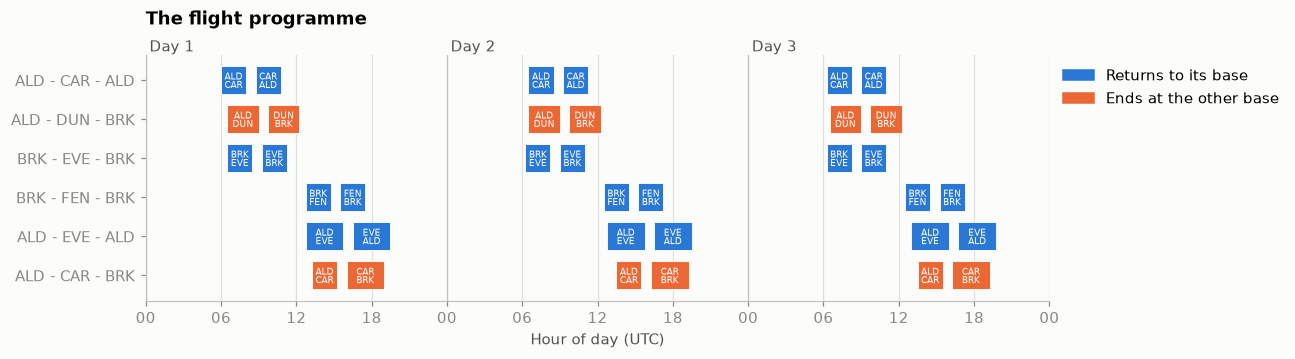

In [3]:
HOURS_SHOWN = np.arange(0, 24 * DAYS + 1, 6)


def hours_from_start(moment):
    return (moment - FIRST_DAY) / timedelta(hours=1)


def set_day_axis(ax):
    ax.set_xticks(HOURS_SHOWN, [f"{h % 24:02d}" for h in HOURS_SHOWN])
    ax.set_xlim(0, 24 * DAYS)
    ax.grid(True, axis="x")
    for day in range(DAYS):
        ax.axvline(24 * day, color="#c3c2b7", linewidth=0.8, zorder=1)
        ax.annotate(f"Day {day + 1}", (24 * day + 0.3, 1), xycoords=("data", "axes fraction"),
                    va="bottom", color=INK)
    ax.set_xlabel("Hour of day (UTC)")


def route_label(flight):
    return f"{flight.departure_airport}\n{flight.arrival_airport}"


def draw_bar(ax, row, flight, color, height=0.72):
    start = hours_from_start(flight.departure_utc_date_time)
    length = hours_from_start(flight.arrival_utc_date_time) - start
    ax.barh(row, length, left=start, height=height, color=color, edgecolor="#fcfcfb", linewidth=0.6, zorder=2)
    ax.text(start + length / 2, row, route_label(flight), ha="center", va="center", color="white",
            fontsize=5.8, linespacing=0.95, zorder=3)


fig, ax = plt.subplots(figsize=(10.6, 2.9))
for f in flights:
    stops = ROTATIONS[rotation_of[f.flight_number]][0]
    draw_bar(ax, rotation_of[f.flight_number], f, COLORS[1] if stops[0] != stops[-1] else COLORS[0])
ax.set_yticks(range(len(ROTATIONS)), [" - ".join(stops) for stops, _ in ROTATIONS])
ax.invert_yaxis()
set_day_axis(ax)
ax.set_title("The flight programme", pad=20)
ax.legend(handles=[Patch(color=COLORS[0], label="Returns to its base"),
                   Patch(color=COLORS[1], label="Ends at the other base")],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 2. Solve it

`fc.solve` takes the model and returns a solved copy, with `employee` filled in on every seat.

The score has two levels, compared in order:

- **hard**: the sum of the rule breaks below, where `0` means the roster can be flown
    - `-100` for each seat given to someone without the skill
    - `-10` for each pair of one person's flights that overlap in time
    - `-1` for each pair of consecutive flights that do not connect, because the first lands somewhere
      other than where the next departs
    - `-10` for each flight that touches a day the person cannot fly
- **soft**: `-1000` when a person's first flight does not leave from home, and `-1000` when their
  last flight does not land at home, where `0` means everyone starts and ends at home

Three things are not in the score, so you should not expect them from the solver: a minimum connection
time (a crew member may land and depart in the same minute), a limit on duty hours, and an even share
of work. A crew member with no flights costs nothing.

In [4]:
SEED, TIME_LIMIT = 42, 3.0

roster = fc.solve(make_schedule(), time_limit_seconds=TIME_LIMIT, random_seed=SEED)

print("feasible:", roster.score_hard == 0)
print("score   :", roster.score_hard, "/", roster.score_soft)
print("unfilled:", [s.id for s in roster.flight_assignments if s.employee is None])

feasible: True
score   : 0 / -12000.0
unfilled: []


### The roster

Each row is one crew member, with their home base beside the name. Each bar is one flight, labelled
with the departure airport above the arrival airport. Red bars are the flights that cost soft score:
a first flight that does not leave from home, or a last flight that does not land there. The right
edge states where each person ends up, and gray bands are the days they cannot fly.

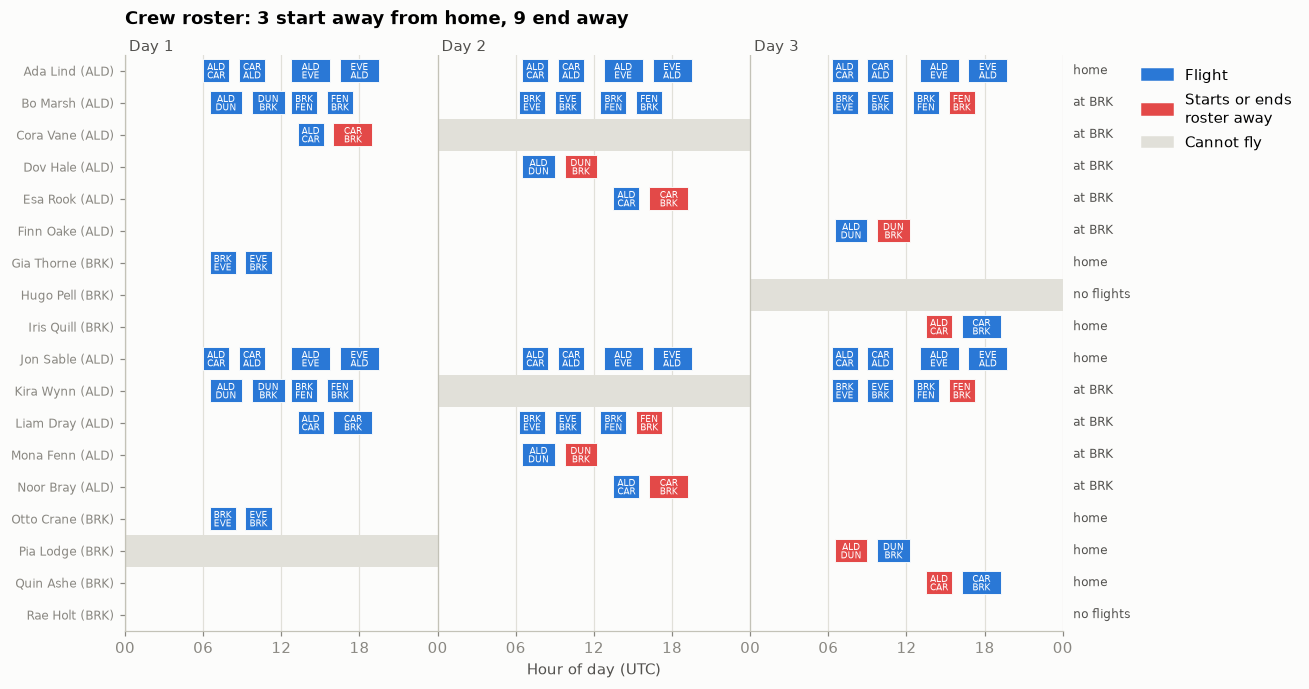

In [5]:
def flights_by_crew(solution):
    """Crew id -> their flights, in departure order."""
    by_number = {f.flight_number: f for f in solution.flights}
    out = {e.id: [] for e in solution.employees}
    for seat in solution.flight_assignments:
        if seat.employee is not None:
            out[seat.employee].append(by_number[seat.flight])
    return {crew: sorted(legs, key=lambda f: f.departure_utc_date_time) for crew, legs in out.items()}


def first_and_last(legs):
    """The flights that open and close a roster, keeping ties as the score does."""
    first = min(f.departure_utc_date_time for f in legs)
    last = max(f.departure_utc_date_time for f in legs)
    return ([f for f in legs if f.departure_utc_date_time == first],
            [f for f in legs if f.departure_utc_date_time == last])


def home_breaks(solution):
    """Crew ids whose roster does not leave from home, and those that do not return there."""
    away_start, away_end, rosters = [], [], flights_by_crew(solution)
    for employee in solution.employees:
        legs = rosters[employee.id]
        if legs:
            opening, closing = first_and_last(legs)
            away_start += [employee.id for f in opening if f.departure_airport != employee.home_airport]
            away_end += [employee.id for f in closing if f.arrival_airport != employee.home_airport]
    return away_start, away_end


def draw_roster(ax, solution):
    rosters = flights_by_crew(solution)
    for row, employee in enumerate(solution.employees):
        legs = rosters[employee.id]
        for day in employee.unavailable_days:
            ax.barh(row, 24, left=24 * (day - FIRST_DAY.date()).days, height=1, color="#e1e0d9", zorder=1)
        opening, closing = first_and_last(legs) if legs else ([], [])
        for f in legs:
            starts_away = f in opening and f.departure_airport != employee.home_airport
            ends_away = f in closing and f.arrival_airport != employee.home_airport
            draw_bar(ax, row, f, COLORS[7] if starts_away or ends_away else COLORS[0])
        outcome = "no flights" if not legs else "home" if legs[-1].arrival_airport == employee.home_airport \
            else f"at {legs[-1].arrival_airport}"
        ax.text(24 * DAYS + 0.8, row, outcome, va="center", color=INK, fontsize=8)
    ax.set_yticks(range(len(solution.employees)),
                  [f"{e.name} ({e.home_airport})" for e in solution.employees], fontsize=8)
    ax.set_ylim(len(solution.employees) - 0.5, -0.5)
    set_day_axis(ax)


away_start, away_end = home_breaks(roster)
fig, ax = plt.subplots(figsize=(11, 6.8))
draw_roster(ax, roster)
ax.set_title(f"Crew roster: {len(away_start)} start away from home, {len(away_end)} end away", pad=20)
ax.legend(handles=[Patch(color=COLORS[0], label="Flight"),
                   Patch(color=COLORS[7], label="Starts or ends\nroster away"),
                   Patch(color="#e1e0d9", label="Cannot fly")],
          loc="upper left", bbox_to_anchor=(1.07, 1))
plt.show()

## 3. Check the result yourself

A solved model is plain data, so the rules can be recomputed from it with no solver code. This walks
each roster and counts every kind of break in the score, then compares the home count with the soft
score. The connection gaps are printed too, because no rule limits them.

In [6]:
def audit(solution):
    """Count rule breaks from the output alone."""
    skills = {e.id: e.skills for e in solution.employees}
    days_off = {e.id: set(e.unavailable_days) for e in solution.employees}
    wrong_skill = sum(s.required_skill not in skills[s.employee] for s in solution.flight_assignments)
    overlaps = no_connection = day_off_flights = 0
    gaps = []
    for crew, legs in flights_by_crew(solution).items():
        for f in legs:
            span = range((f.arrival_utc_date_time.date() - f.departure_utc_date_time.date()).days + 1)
            dates = {f.departure_utc_date_time.date() + timedelta(days=d) for d in span}
            day_off_flights += bool(dates & days_off[crew])
        overlaps += sum(b.departure_utc_date_time < a.arrival_utc_date_time for a, b in combinations(legs, 2))
        for a, b in zip(legs, legs[1:]):
            no_connection += a.arrival_airport != b.departure_airport
            gaps.append((b.departure_utc_date_time - a.arrival_utc_date_time) / timedelta(minutes=1))
    return {"wrong skill": wrong_skill, "overlapping flights": overlaps, "broken connections": no_connection,
            "flights on a day off": day_off_flights, "gaps": gaps}


check = audit(roster)
for rule in ("wrong skill", "overlapping flights", "broken connections", "flights on a day off"):
    print(f"{rule:22}: {check[rule]}")
print(f"home breaks            : {len(away_start)} + {len(away_end)}, "
      f"which is soft {-1000 * (len(away_start) + len(away_end))}, solver says {roster.score_soft:.0f}")
print(f"tightest connection    : {min(check['gaps']):.0f} minutes")

legs_flown = {e.name: len(flights_by_crew(roster)[e.id]) for e in roster.employees}
print(f"flights per person     : {min(legs_flown.values())} to {max(legs_flown.values())}")

wrong skill           : 0
overlapping flights   : 0
broken connections    : 0
flights on a day off  : 0
home breaks            : 3 + 9, which is soft -12000, solver says -12000
tightest connection    : 30 minutes
flights per person     : 0 to 12


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and passing
`constraints=` to `fc.solve` replaces the set. Only listed rules are scored, so leave one out and its
term disappears.

`weight` scales a rule, `hard` moves it between levels, and `exponent=2` makes large violations much
costlier than small ones.

In [7]:
for name in fc.list_constraints():
    print(name)

required_skill
flight_conflict
transfer_between_two_flights
employee_unavailability
first_assignment_not_departing_from_home
last_assignment_not_arriving_at_home


So far a broken connection is forbidden, even though an airline can move a crew member by car or as a
passenger. Suppose that transfer has a price. Making `TransferBetweenTwoFlights` a soft rule with
`weight=100` says one transfer costs a tenth of a roster that starts or ends away from home, so the
solver may now buy transfers to bring people back.

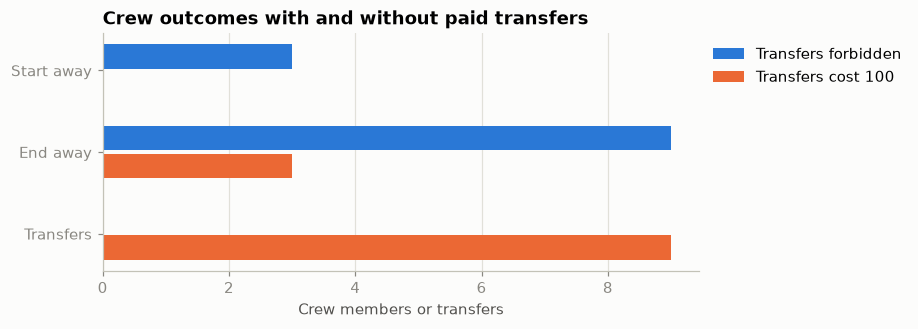

forbidden: score 0 / -12000, {'Start away': 3, 'End away': 9, 'Transfers': 0}
paid     : score 0 / -3900, {'Start away': 0, 'End away': 3, 'Transfers': 9}


In [8]:
TRANSFER_PRICE = 100
paid_transfers = rules.get_constraints([
    rules.required_skill,
    rules.flight_conflict,
    rules.employee_unavailability,
    rules.first_assignment_not_departing_from_home,
    rules.last_assignment_not_arriving_at_home,
    rules.TransferBetweenTwoFlights(weight=TRANSFER_PRICE, hard=False),
])

relaxed = fc.solve(make_schedule(), time_limit_seconds=TIME_LIMIT, random_seed=SEED, constraints=paid_transfers)


def outcome_counts(solution):
    start, end = home_breaks(solution)
    return {"Start away": len(start), "End away": len(end), "Transfers": audit(solution)["broken connections"]}


before, after = outcome_counts(roster), outcome_counts(relaxed)
y = np.arange(len(before))
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(y - 0.17, list(before.values()), height=0.3, color=COLORS[0], label="Transfers forbidden")
ax.barh(y + 0.17, list(after.values()), height=0.3, color=COLORS[1], label=f"Transfers cost {TRANSFER_PRICE}")
ax.set_yticks(y, list(before))
ax.invert_yaxis()
ax.set(title="Crew outcomes with and without paid transfers", xlabel="Crew members or transfers")
ax.grid(True, axis="x")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"forbidden: score {roster.score_hard} / {roster.score_soft:.0f}, {before}")
print(f"paid     : score {relaxed.score_hard} / {relaxed.score_soft:.0f}, {after}")

The two scores are not comparable, because they use different rules. Compare what happened to the crew
instead: the counts above come from the rosters, not from the scores. Both are the best found in the
time limit rather than proven optima, and section 6 shows how far one run can be from another.

## 5. Too few crew

Airborne flights are not the whole demand. Every crew member's flights must form one connected chain,
so the flight network needs a certain number of chains per seat. Here pilots and attendants shrink
together, with people leaving both bases. A wrong skill or an overlap costs more than a broken connection,
so the printed audit shows which rule the solver gives up.

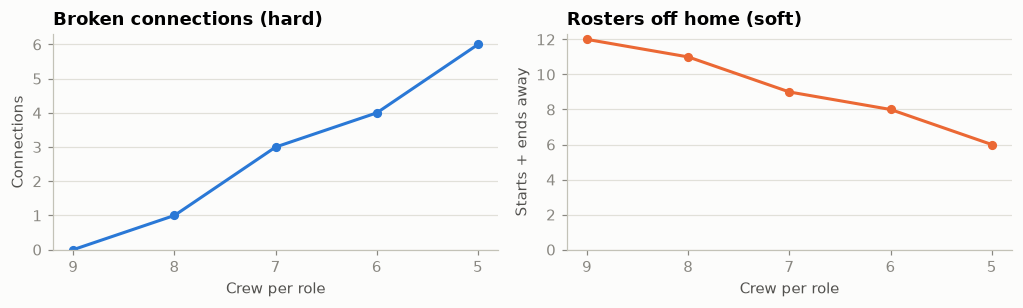

hard score by crew size : {9: 0, 8: -1, 7: -3, 6: -4, 5: -6}
overlaps by crew size   : {9: 0, 8: 0, 7: 0, 6: 0, 5: 0}


In [9]:
sizes, hard_scores, transfers, overlapping, away = [], [], [], [], []
for count in [9, 8, 7, 6, 5]:
    crew = make_crew(PILOTS[:count - count // 3] + PILOTS[6:6 + count // 3],
                     ATTENDANTS[:count - count // 2] + ATTENDANTS[5:5 + count // 2])
    small = fc.solve(make_schedule(crew), time_limit_seconds=1.5, random_seed=SEED)
    start, end = home_breaks(small)
    sizes.append(count)
    hard_scores.append(small.score_hard)
    transfers.append(audit(small)["broken connections"])
    overlapping.append(audit(small)["overlapping flights"])
    away.append(len(start) + len(end))

fig, axes = plt.subplots(1, 2, figsize=(9.4, 2.9), sharex=True)
axes[0].plot(sizes, transfers, color=COLORS[0], linewidth=2, marker="o", markersize=5)
axes[0].set(title="Broken connections (hard)", xlabel="Crew per role", ylabel="Connections")
axes[1].plot(sizes, away, color=COLORS[1], linewidth=2, marker="o", markersize=5)
axes[1].set(title="Rosters off home (soft)", xlabel="Crew per role", ylabel="Starts + ends away")
for ax in axes:
    ax.set_xticks(sizes)
    ax.grid(True, axis="y")
    ax.set_ylim(bottom=0)
axes[0].invert_xaxis()  # the axes share x, so one call flips both
plt.tight_layout()
plt.show()
print("hard score by crew size :", dict(zip(sizes, hard_scores)))
print("overlaps by crew size   :", dict(zip(sizes, overlapping)))

Read the right-hand chart with care. Fewer people means fewer rosters that can start or end away, so a
lower count there does not mean a better plan. The left-hand chart is the one that says the crew is too
small.

## 6. Restart from an existing roster

`with_initial_solution(problem, solution)` returns a copy of `problem` whose search starts from
`solution`. A complete solution is exactly where the search starts, so a later solve continues the work
instead of building a new roster.

This matters here because a run can stall. One seat cannot usually change hands without breaking a
connection, so the search depends on ruin and recreate, which clears several seats at once. Turn it off
and compare, then look at how far apart short runs land with different seeds.

In [10]:
ROUND_SECONDS = 0.3


def paid_solve(start=None, seed=0, **options):
    """One short search on the paid-transfer rules, from nothing or from an earlier roster."""
    config = fc.SolverConfig()
    config.spent_limit_seconds = ROUND_SECONDS
    config.random_seed = seed
    for option, value in options.items():
        setattr(config, option, value)
    schedule = make_schedule() if start is None else fc.with_initial_solution(make_schedule(), start)
    return fc.solve(schedule, config=config, constraints=paid_transfers)


one_second = dict(seed=1, spent_limit_seconds=1.0)
print("ruin and recreate off, 1 s:", paid_solve(ruin_recreate=False, **one_second).score_soft)
print("ruin and recreate on, 1 s :", paid_solve(**one_second).score_soft)
print("six seeds, each 0.3 s     :", sorted(paid_solve(seed=seed).score_soft for seed in range(6)))

ruin and recreate off, 1 s: -4800.0
ruin and recreate on, 1 s : -3000.0
six seeds, each 0.3 s     : [-3900.0, -3900.0, -3500.0, -3000.0, -3000.0, -3000.0]


**Give each restart its own `random_seed`.** The same start with the same seed repeats the same search,
so once a round finds nothing, every later round returns the same roster. Both lines below begin from
the same first answer. The printed count shows how many rounds returned the roster they started from.

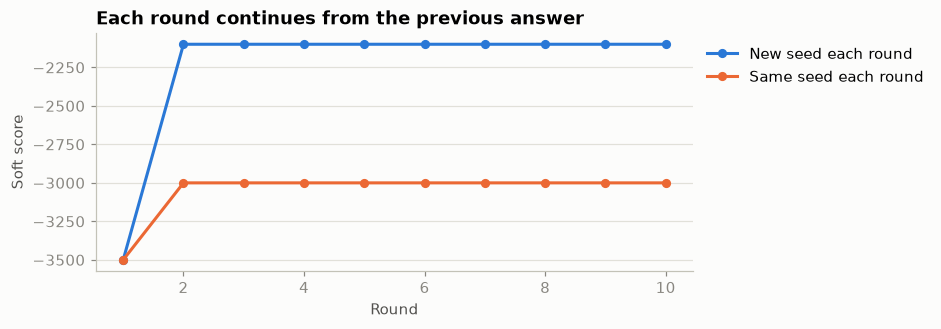

same seed: 8 of 9 restarts returned their starting roster
new seed : 8 of 9 restarts returned their starting roster


In [11]:
ROUNDS, FIRST_SEED = 10, 1


first_answer = paid_solve(seed=FIRST_SEED)


def run_rounds(seed_of_round):
    solution = first_answer
    history, repeats = [solution.score_soft], 0
    for round_number in range(1, ROUNDS):
        previous = [seat.employee for seat in solution.flight_assignments]
        solution = paid_solve(solution, seed=seed_of_round(round_number))
        history.append(solution.score_soft)
        repeats += [seat.employee for seat in solution.flight_assignments] == previous
    return history, repeats


same_seed, same_repeats = run_rounds(lambda round_number: FIRST_SEED)
new_seed, new_repeats = run_rounds(lambda round_number: FIRST_SEED + 10 * round_number)

fig, ax = plt.subplots(figsize=(7, 2.8))
turns = range(1, ROUNDS + 1)
ax.plot(turns, new_seed, color=COLORS[0], linewidth=2, marker="o", markersize=5, label="New seed each round")
ax.plot(turns, same_seed, color=COLORS[1], linewidth=2, marker="o", markersize=5, label="Same seed each round")
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="Soft score")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"same seed: {same_repeats} of {ROUNDS - 1} restarts returned their starting roster")
print(f"new seed : {new_repeats} of {ROUNDS - 1} restarts returned their starting roster")

A new seed does not guarantee progress. When the blue line levels off, the search has stalled, which is
not a proof that the roster is optimal: another chain of seeds can land somewhere better. The answer is
the best found in these rounds.

### Replan around a sick call

The first day has been flown when the crew member with the most flights left reports sick for the
other two days. Flown seats cannot change, so they are **pinned**: a pinned seat keeps its `employee`
whatever the solution says, counts in the score, and never moves.

Nothing in the score rewards keeping a roster stable, and a roster that changes on the morning of a
flight has a real cost, so this compares three replans by the seats they move as well as by the score:

- **Day 1 pinned, old roster**: the search starts from the old roster and may move any open seat.
- **Day 1 pinned, no roster**: the same pins, with the open seats built again.
- **Only sick seats open**: every seat is pinned except the sick person's remaining seats.

Ada Lind is sick, with 8 flights left to cover
Day 1 pinned, old roster : score 0 / -14000, 42 seats moved, pins kept: True
Day 1 pinned, no roster  : score -1 / -11000, 16 seats moved, pins kept: True
Only sick seats open     : score -1 / -11000, 8 seats moved, pins kept: True


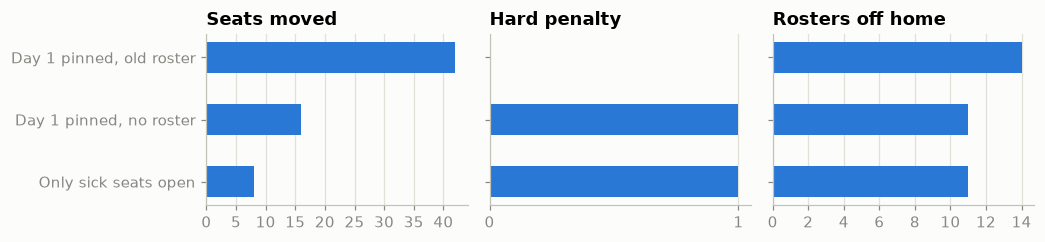

In [12]:
REPLAN_SECONDS, REPLAN_SEED = 1.0, SEED + 1
flown_until = FIRST_DAY + timedelta(days=1)
by_number = {f.flight_number: f for f in flights}
seat_crew = {s.id: s.employee for s in roster.flight_assignments}

flights_left = {crew: sum(f.departure_utc_date_time >= flown_until for f in legs)
                for crew, legs in flights_by_crew(roster).items()}
sick_id = max(flights_left, key=flights_left.get)


def replanning_problem(keep):
    """The schedule with the sick days added, and every seat where keep(seat) is true pinned."""
    schedule = make_schedule()
    sick = next(e for e in schedule.employees if e.id == sick_id)
    sick.unavailable_days = sorted({*sick.unavailable_days, date(2030, 3, 5), date(2030, 3, 6)})
    for seat in schedule.flight_assignments:
        if keep(seat):
            seat.employee, seat.pinned = seat_crew[seat.id], True
    return schedule


def is_flown(seat):
    return by_number[seat.flight].departure_utc_date_time < flown_until


def is_kept(seat):
    return is_flown(seat) or seat_crew[seat.id] != sick_id


def changed_seats(solution):
    return [s.id for s in solution.flight_assignments if s.employee != seat_crew[s.id]]


replans = {
    "Day 1 pinned, old roster": fc.with_initial_solution(replanning_problem(is_flown), roster),
    "Day 1 pinned, no roster": replanning_problem(is_flown),
    "Only sick seats open": fc.with_initial_solution(replanning_problem(is_kept), roster),
}
replans = {name: fc.solve(schedule, time_limit_seconds=REPLAN_SECONDS, random_seed=REPLAN_SEED)
           for name, schedule in replans.items()}

print(f"{next(e.name for e in roster.employees if e.id == sick_id)} is sick, "
      f"with {flights_left[sick_id]} flights left to cover")
for name, plan in replans.items():
    kept = all(s.employee == seat_crew[s.id] for s in plan.flight_assignments if s.pinned)
    print(f"{name:25}: score {plan.score_hard} / {plan.score_soft:.0f}, "
          f"{len(changed_seats(plan))} seats moved, pins kept: {kept}")

names = list(replans)
y = np.arange(len(names))
panels = [("Seats moved", [len(changed_seats(p)) for p in replans.values()]),
          ("Hard penalty", [-p.score_hard for p in replans.values()]),
          ("Rosters off home", [-p.score_soft / 1000 for p in replans.values()])]
fig, axes = plt.subplots(1, 3, figsize=(9.6, 2.3), sharey=True)
for ax, (title, values) in zip(axes, panels):
    ax.barh(y, values, height=0.5, color=COLORS[0])
    ax.set_title(title)
    ax.set_xlim(0, max(*values, 1) * 1.05)
    ax.grid(True, axis="x")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_yticks(y, names)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

Below is the replan that moves the fewest seats, which is the one a duty manager would look at first.
Outlined bars are the flights that changed hands, and the title reports what that plan still breaks.

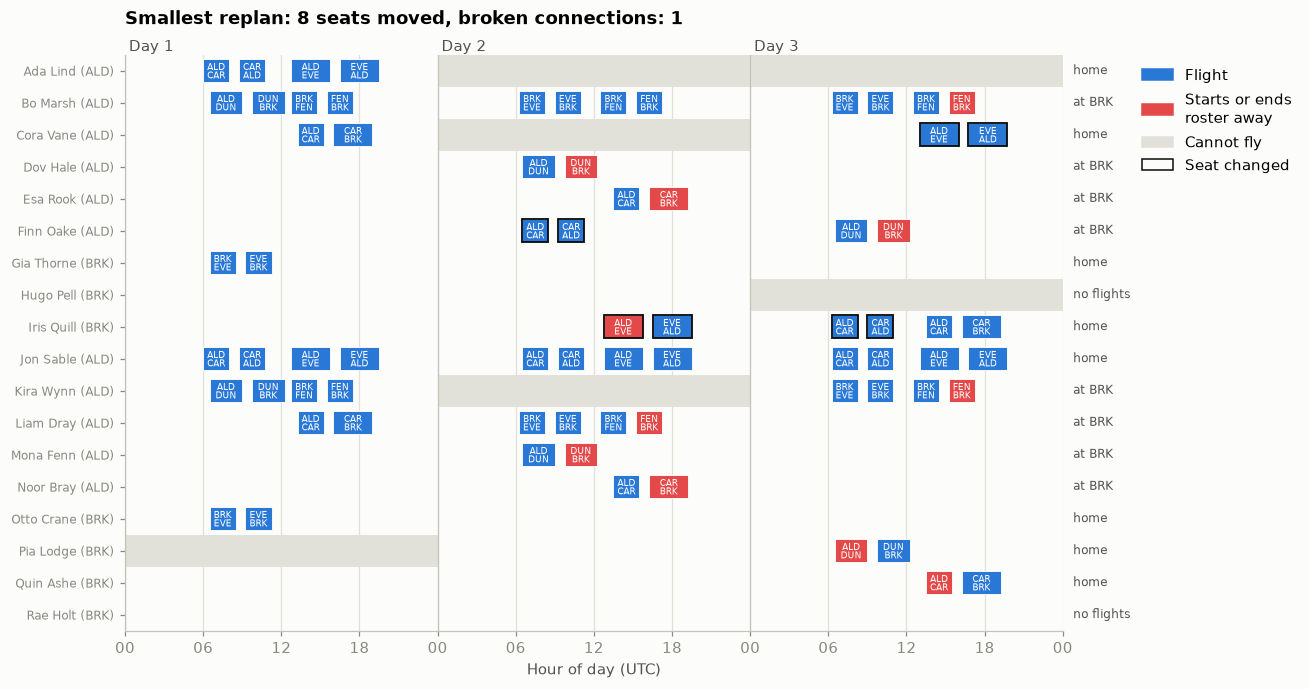

In [13]:
smallest = min(replans.values(), key=lambda plan: len(changed_seats(plan)))
moved = set(changed_seats(smallest))

fig, ax = plt.subplots(figsize=(11, 6.8))
draw_roster(ax, smallest)
crew_row = {e.id: row for row, e in enumerate(smallest.employees)}
for seat in smallest.flight_assignments:
    if seat.id in moved:
        flight = by_number[seat.flight]
        start = hours_from_start(flight.departure_utc_date_time)
        length = hours_from_start(flight.arrival_utc_date_time) - start
        ax.barh(crew_row[seat.employee], length, left=start, height=0.72, color="none",
                edgecolor="#0b0b0b", linewidth=1.2, zorder=4)
ax.set_title(f"Smallest replan: {len(moved)} seats moved, "
             f"broken connections: {audit(smallest)['broken connections']}", pad=20)
ax.legend(handles=[Patch(color=COLORS[0], label="Flight"),
                   Patch(color=COLORS[7], label="Starts or ends\nroster away"),
                   Patch(color="#e1e0d9", label="Cannot fly"),
                   Patch(facecolor="none", edgecolor="#0b0b0b", label="Seat changed")],
          loc="upper left", bbox_to_anchor=(1.07, 1))
plt.show()

## Next steps

- `use-cases/flight-crew-scheduling/README.md` covers the basic solver options and how to add your
  own rules in C++, which is where a minimum connection time or a duty limit would go.
- For rosters built from shifts instead of flights, see `employee-scheduling.ipynb`.